In [ ]:
#Import libraries
import pandas as pd

In [ ]:
# Load datasets (update path as needed)

orders = pd.read_csv("/content/olist_orders_dataset.csv")
order_items = pd.read_csv("/content/olist_order_items_dataset.csv")
products = pd.read_csv("/content/olist_products_dataset.csv")
customers = pd.read_csv("/content/olist_customers_dataset.csv")
payments = pd.read_csv("/content/olist_order_payments_dataset.csv")
reviews = pd.read_csv("/content/olist_order_reviews_dataset.csv")
geolocation = pd.read_csv("/content/olist_geolocation_dataset.csv")


In [ ]:
# Aggregate geolocation to one row per zip code prefix
geo_cleaned = geolocation.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'mean',
    'geolocation_lng': 'mean',
    'geolocation_city': 'first',
    'geolocation_state': 'first'
}).reset_index()

print("Original Geolocation Shape:", geolocation.shape)
print("Aggregated Geolocation Shape:", geo_cleaned.shape)
display(geo_cleaned.head(5))


Original Geolocation Shape: (1000163, 5)
Aggregated Geolocation Shape: (19015, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1001,-23.550190,-46.634024,sao paulo,SP
1,1002,-23.548146,-46.634979,sao paulo,SP
2,1003,-23.548994,-46.635731,sao paulo,SP
3,1004,-23.549799,-46.634757,sao paulo,SP
4,1005,-23.549456,-46.636733,sao paulo,SP


In [ ]:
# Create dictionary for looping
datasets = {
    "Orders": orders,
    "Order_Items": order_items,
    "Products": products,
    "Customers": customers,
    "Payments": payments,
    "Reviews": reviews,
    "Geolocation (Aggregated)": geo_cleaned
}

# Print shape and sample rows
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    display(df.head(3))



--- Orders ---
Shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00



--- Order_Items ---
Shape: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87



--- Products ---
Shape: (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


... (4 outputs left out)


--- Reviews ---
Shape: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24



--- Geolocation (Aggregated) ---
Shape: (19015, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1001,-23.550190,-46.634024,sao paulo,SP
1,1002,-23.548146,-46.634979,sao paulo,SP
2,1003,-23.548994,-46.635731,sao paulo,SP


In [ ]:
# Info about each dataset
for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print(df.info())



--- Orders ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None

--- Order_Items ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ord

In [ ]:
# Orders -> Customers
print("\nUnique customers in Orders:", orders['customer_id'].nunique())
print("Unique customers in Customers table:", customers['customer_id'].nunique())

# Orders -> Payments
print("\nPayments linked to Orders:", payments['order_id'].nunique())
print("Orders in Orders table:", orders['order_id'].nunique())

# Orders -> Reviews
print("\nReviews linked to Orders:", reviews['order_id'].nunique())

# Orders -> Products (through Order_Items)
print("\nProducts linked via Order_Items:", order_items['product_id'].nunique())
print("Products in Products table:", products['product_id'].nunique())



Unique customers in Orders: 99441
Unique customers in Customers table: 99441

Payments linked to Orders: 99440
Orders in Orders table: 99441

Reviews linked to Orders: 98673

Products linked via Order_Items: 32951
Products in Products table: 32951


In [ ]:
print("""
Entity Relationships:
- Customers place Orders.
- Each Order has one or more Order_Items (products).
- Each Order_Item belongs to a Product.
- Orders are linked to Payments.
- Orders may have Reviews.
- Customers are mapped to regions using Geolocation (by zip code prefix).
""")



Entity Relationships:
- Customers place Orders.
- Each Order has one or more Order_Items (products).
- Each Order_Item belongs to a Product.
- Orders are linked to Payments.
- Orders may have Reviews.
- Customers are mapped to regions using Geolocation (by zip code prefix).



###Data Cleaning & Preprocessing

In [ ]:
# Check missing values in each dataset
for name, df in datasets.items():
    print(f"\n{name} Missing Values:\n", df.isnull().sum())



Orders Missing Values:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Order_Items Missing Values:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Products Missing Values:
 product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Customers Missing Values:
 customer_id                 0
customer_unique_id          0
custom

In [ ]:
# Remove exact duplicate rows
for name, df in datasets.items():
    before = df.shape[0]
    df.drop_duplicates(inplace=True)
    after = df.shape[0]
    print(f"{name}: Removed {before - after} duplicates")


Orders: Removed 0 duplicates
Order_Items: Removed 0 duplicates
Products: Removed 0 duplicates
Customers: Removed 0 duplicates
Payments: Removed 0 duplicates
Reviews: Removed 0 duplicates
Geolocation (Aggregated): Removed 0 duplicates


In [ ]:
#  Handle missing values according to rules

# Orders: drop rows with missing critical dates (after filtering later)
orders = orders.dropna(subset=['order_purchase_timestamp'])

# Payments: drop if payment_value missing, fill payment_type if missing
payments = payments.dropna(subset=['payment_value'])
payments['payment_type'].fillna("unknown", inplace=True)

# Customers: drop if customer_id missing
customers = customers.dropna(subset=['customer_id'])

# Products: fill missing category with 'unknown'
products['product_category_name'].fillna("unknown", inplace=True)

# Reviews: keep missing comments as-is (normal)
# Geolocation: already aggregated (geo_cleaned)


/tmp/ipython-input-2572188180.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  payments['payment_type'].fillna("unknown", inplace=True)
/tmp/ipython-input-2572188180.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)

In [ ]:
# Convert datetime columns in Orders dataset
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

print(orders[date_cols].dtypes)


order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [ ]:
# Filter orders to keep only delivered ones
orders = orders[orders['order_status'] == 'delivered'].copy()

# Drop rows with missing final delivery date
orders = orders.dropna(subset=['order_delivered_customer_date'])

print("Remaining Delivered Orders:", orders.shape[0])


Remaining Delivered Orders: 96470


In [ ]:
# Merge Orders + Customers
orders_customers = orders.merge(customers, on="customer_id", how="left")

# Merge with Payments
orders_payments = orders_customers.merge(payments, on="order_id", how="left")

# Merge with Order Items
orders_items = orders_payments.merge(order_items, on="order_id", how="left")

# Merge with Products
master_data = orders_items.merge(products, on="product_id", how="left")

print("Master Dataset Shape:", master_data.shape)
display(master_data.head(5))


Master Dataset Shape: (115030, 30)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0


In [ ]:
# Summary of cleaned master dataset
print("Unique Customers:", master_data['customer_id'].nunique())
print("Unique Orders:", master_data['order_id'].nunique())
print("Unique Products:", master_data['product_id'].nunique())
print("Total Revenue (payments):", master_data['payment_value'].sum())

print("Date Range:", master_data['order_purchase_timestamp'].min(), "to", master_data['order_purchase_timestamp'].max())


Unique Customers: 96470
Unique Orders: 96470
Unique Products: 32214
Total Revenue (payments): 19774781.52
Date Range: 2016-09-15 12:16:38 to 2018-08-29 15:00:37


##Plan – Sales Analysis

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
plt.style.use("default")
sns.set_theme()


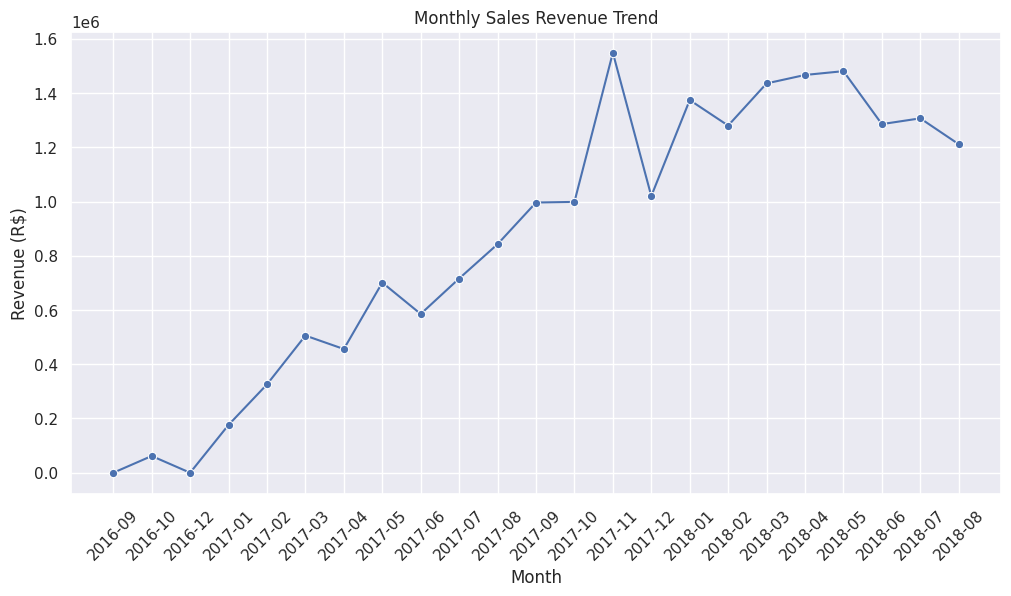

In [ ]:
# Extract month-year from order purchase date
master_data['order_month'] = master_data['order_purchase_timestamp'].dt.to_period('M')

# Aggregate monthly revenue
monthly_sales = master_data.groupby('order_month')['payment_value'].sum().reset_index()

# Convert back to datetime for plotting
monthly_sales['order_month'] = monthly_sales['order_month'].astype(str)

# Plot
plt.figure(figsize=(12,6))
sns.lineplot(data=monthly_sales, x='order_month', y='payment_value', marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Sales Revenue Trend")
plt.ylabel("Revenue (R$)")
plt.xlabel("Month")
plt.show()


/tmp/ipython-input-1752918195.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_categories, x='payment_value', y='product_category_name', palette="Blues_r")


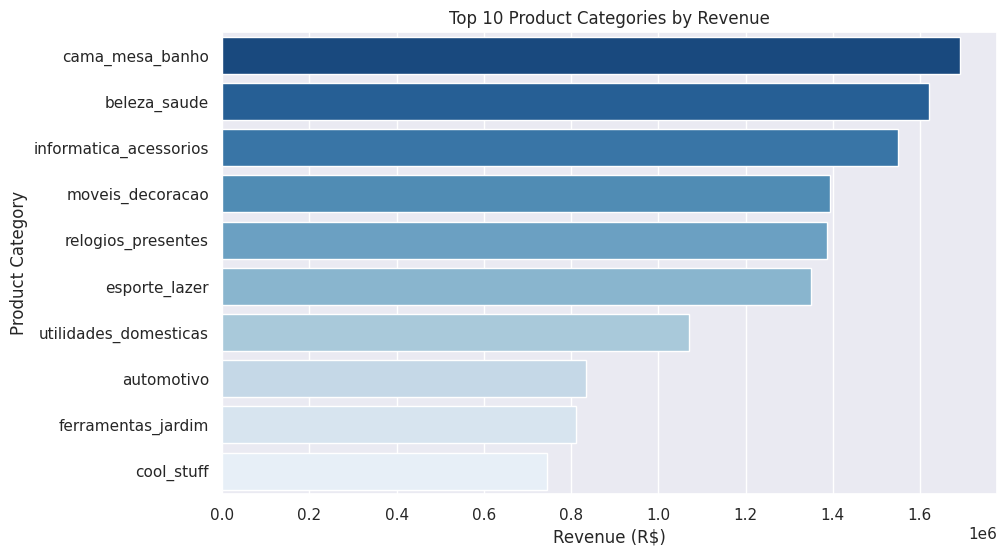

In [ ]:
# Revenue by product category
category_sales = master_data.groupby('product_category_name')['payment_value'].sum().reset_index()

# Sort and take top 10
top_categories = category_sales.sort_values(by='payment_value', ascending=False).head(10)

# Plot
plt.figure(figsize=(10,6))
sns.barplot(data=top_categories, x='payment_value', y='product_category_name', palette="Blues_r")
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")
plt.show()


In [ ]:
# AOV = Total Revenue / Number of Unique Orders
total_revenue = master_data['payment_value'].sum()
total_orders = master_data['order_id'].nunique()
aov = total_revenue / total_orders

print(f"Total Revenue: R$ {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value (AOV): R$ {aov:,.2f}")


Total Revenue: R$ 19,774,781.52
Total Orders: 96,470
Average Order Value (AOV): R$ 204.98


In [ ]:
print(customers.columns)


Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')


/tmp/ipython-input-1701308597.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_sales.head(10), x='geolocation_state', y='payment_value', palette="viridis")


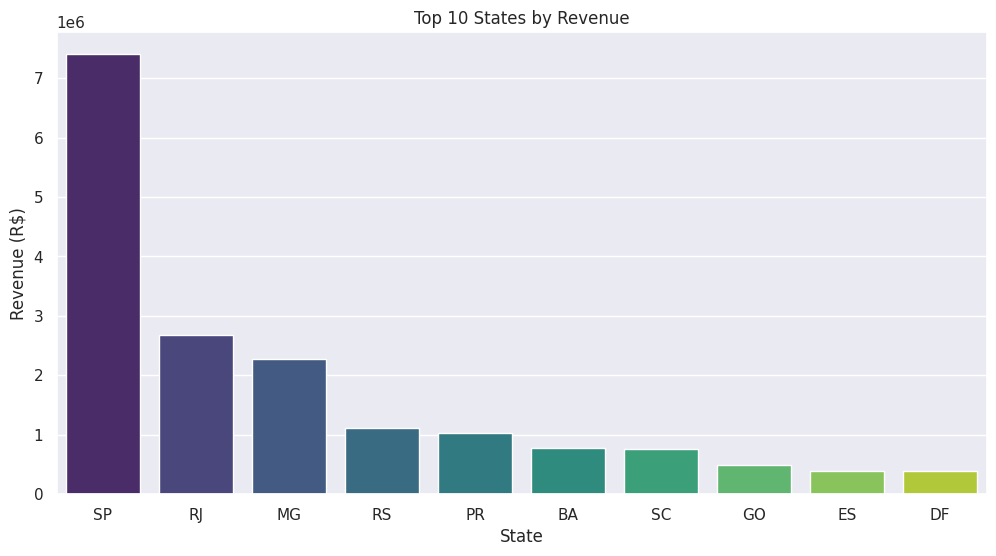

In [ ]:
# Corrected: Sales by State

# Merge master dataset directly with aggregated geolocation
master_geo = master_data.merge(
    geo_cleaned,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)

# Revenue by state
state_sales = master_geo.groupby('geolocation_state')['payment_value'].sum().reset_index().sort_values(by='payment_value', ascending=False)

# Plot
plt.figure(figsize=(12,6))
sns.barplot(data=state_sales.head(10), x='geolocation_state', y='payment_value', palette="viridis")
plt.title("Top 10 States by Revenue")
plt.xlabel("State")
plt.ylabel("Revenue (R$)")
plt.show()


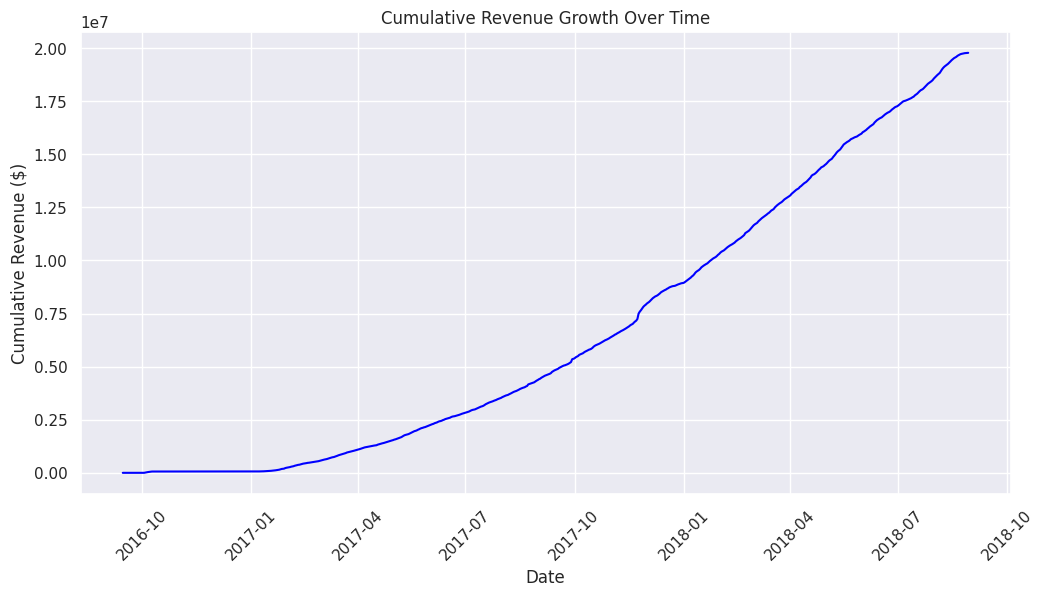

In [ ]:
# Cumulative Revenue Growth Over Time

# Group sales by purchase date (daily granularity)
daily_sales = master_data.groupby(master_data['order_purchase_timestamp'].dt.date)['payment_value'].sum().reset_index()

# Sort by date
daily_sales = daily_sales.sort_values(by='order_purchase_timestamp')

# Add cumulative revenue column
daily_sales['cumulative_revenue'] = daily_sales['payment_value'].cumsum()

# Plot
plt.figure(figsize=(12,6))
sns.lineplot(data=daily_sales, x='order_purchase_timestamp', y='cumulative_revenue', color="blue")
plt.title("Cumulative Revenue Growth Over Time")
plt.xlabel("Date")
plt.ylabel("Cumulative Revenue ($)")
plt.xticks(rotation=45)
plt.show()


##Customer Analysis

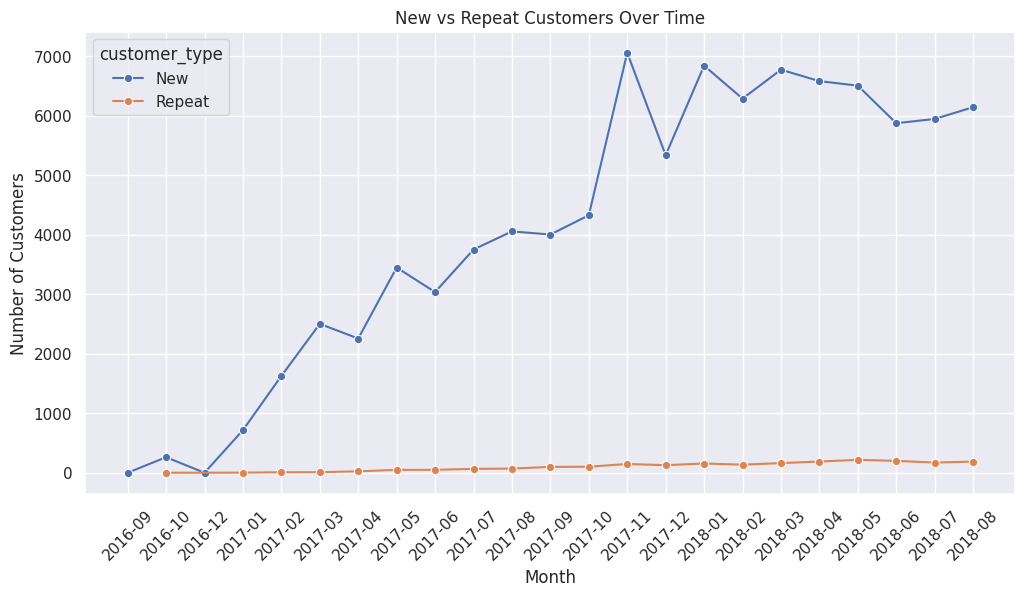

In [ ]:
# Identify each customer's first purchase date
customer_first_purchase = master_data.groupby('customer_unique_id')['order_purchase_timestamp'].min().reset_index()
customer_first_purchase.columns = ['customer_unique_id', 'first_purchase_date']

# Merge back with master_data
customer_orders = master_data.merge(customer_first_purchase, on='customer_unique_id', how='left')

# Create a flag: New if order = first purchase, else Repeat
customer_orders['customer_type'] = customer_orders.apply(
    lambda x: "New" if x['order_purchase_timestamp'].date() == x['first_purchase_date'].date() else "Repeat",
    axis=1
)

# Convert order month to string (YYYY-MM)
customer_orders['order_month'] = customer_orders['order_purchase_timestamp'].dt.to_period('M').astype(str)

# Count new vs repeat customers per month
new_repeat_trend = customer_orders.groupby(['order_month', 'customer_type'])['customer_unique_id'].nunique().reset_index()

# Plot
plt.figure(figsize=(12,6))
sns.lineplot(data=new_repeat_trend, x='order_month', y='customer_unique_id', hue='customer_type', marker="o")
plt.xticks(rotation=45)
plt.title("New vs Repeat Customers Over Time")
plt.ylabel("Number of Customers")
plt.xlabel("Month")
plt.show()


###Cohort Retention Analysis

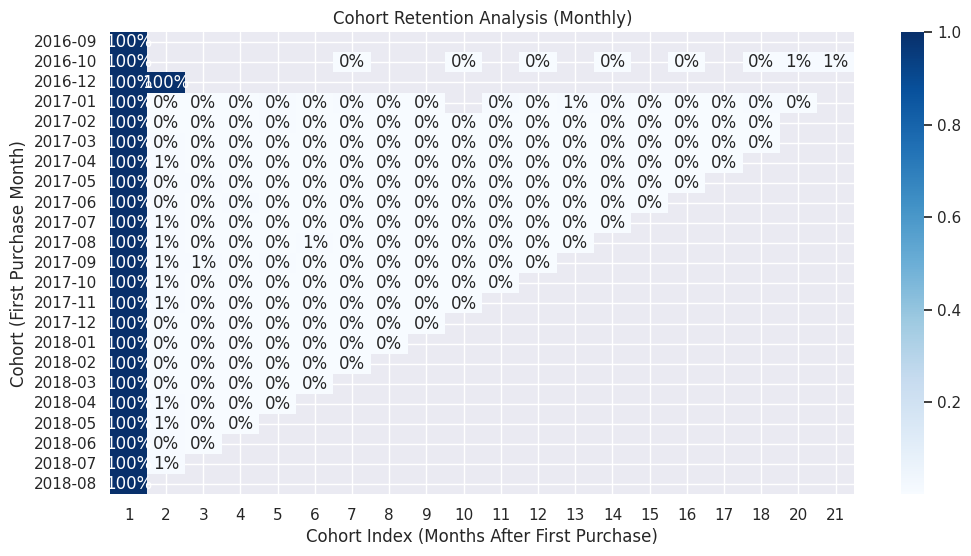

In [ ]:
# Convert dates properly
customer_orders['order_month'] = customer_orders['order_purchase_timestamp'].dt.to_period('M')
customer_orders['cohort_month'] = customer_orders.groupby('customer_unique_id')['order_purchase_timestamp'] \
                                                 .transform('min').dt.to_period('M')

# Cohort index: months between order and first purchase
def get_cohort_index(order_month, cohort_month):
    return (order_month.year - cohort_month.year) * 12 + (order_month.month - cohort_month.month) + 1

customer_orders['cohort_index'] = customer_orders.apply(
    lambda row: get_cohort_index(row['order_month'], row['cohort_month']), axis=1
)

# Group by cohort month + cohort index
cohort_data = customer_orders.groupby(['cohort_month','cohort_index'])['customer_unique_id'].nunique().reset_index()

# Pivot: Cohort Month as rows, Cohort Index as columns
cohort_pivot = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

# Normalize: divide by first column (Month 1 customers)
cohort_retention = cohort_pivot.divide(cohort_pivot.iloc[:,0], axis=0)

# Plot heatmap
plt.figure(figsize=(12,6))
sns.heatmap(cohort_retention, annot=True, fmt=".0%", cmap="Blues")
plt.title("Cohort Retention Analysis (Monthly)")
plt.ylabel("Cohort (First Purchase Month)")
plt.xlabel("Cohort Index (Months After First Purchase)")
plt.show()


###RFM Segmentation

/tmp/ipython-input-3892193496.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_counts, x='Count', y='Segment', palette="viridis")


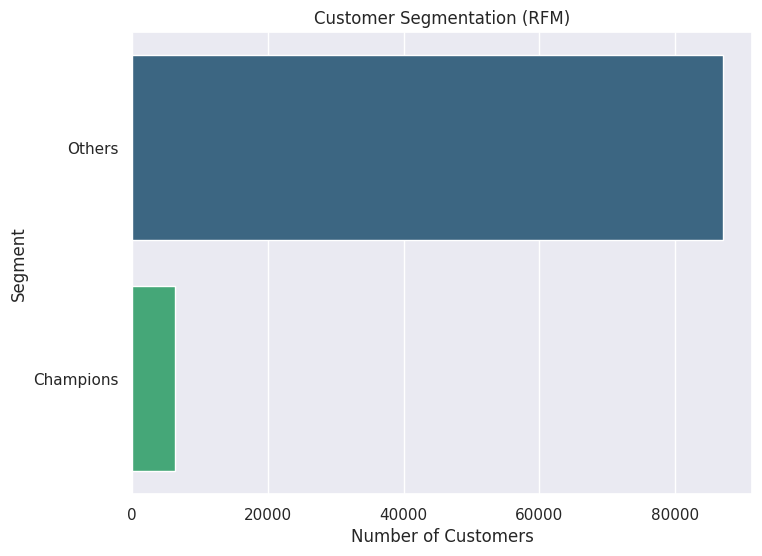

,customer_unique_id,Recency,Frequency,Monetary,R,F,M,RFM_Score,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,3,413,Others
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,3,1,1,311,Others
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,112,Others
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,211,Others
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,3,213,Others
5,0004bd2a26a76fe21f786e4fbd80607f,146,1,166.98,3,1,3,313,Others
6,00050ab1314c0e55a6ca13cf7181fecf,132,1,35.38,3,1,1,311,Others
7,00053a61a98854899e70ed204dd4bafe,183,1,838.36,3,1,4,314,Others
8,0005e1862207bf6ccc02e4228effd9a0,543,1,150.12,1,1,3,113,Others
9,0005ef4cd20d2893f0d9fbd94d3c0d97,170,1,129.76,3,1,3,313,Others


In [ ]:
# Today's date = last order date in dataset + 1 day
today_date = master_data['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# Compute Recency, Frequency, Monetary
rfm = master_data.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (today_date - x.max()).days,
    'order_id': 'nunique',
    'payment_value': 'sum'
}).reset_index()

rfm.columns = ['customer_unique_id','Recency','Frequency','Monetary']

# Assign RFM scores (quartiles) → use rank to handle duplicates
rfm['R'] = pd.qcut(rfm['Recency'], 4, labels=[4,3,2,1])  # Lower recency → better
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method="first"), 4, labels=[1,2,3,4])
rfm['M'] = pd.qcut(rfm['Monetary'].rank(method="first"), 4, labels=[1,2,3,4])

# Combine into RFM Score
rfm['RFM_Score'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)

# Simple Segmentation Logic
def segment_customer(row):
    if row['RFM_Score'] in ['444','443','434','344']:
        return "Champions"
    elif row['R'] == '4':
        return "Loyal Customers"
    elif row['M'] == '4':
        return "Big Spenders"
    elif row['R'] == '1':
        return "At Risk"
    else:
        return "Others"

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

# Count customers by segment
segment_counts = rfm['Segment'].value_counts().reset_index()
segment_counts.columns = ['Segment','Count']

# Plot Segments
plt.figure(figsize=(8,6))
sns.barplot(data=segment_counts, x='Count', y='Segment', palette="viridis")
plt.title("Customer Segmentation (RFM)")
plt.xlabel("Number of Customers")
plt.ylabel("Segment")
plt.show()

# Show sample RFM table
display(rfm.head(10))


##Sales Forecasting

In [ ]:
# Aggregate sales by month
monthly_sales = master_data.groupby(master_data['order_purchase_timestamp'].dt.to_period('M'))['payment_value'].sum().reset_index()

# Convert Period to datetime for modeling
monthly_sales['order_purchase_timestamp'] = monthly_sales['order_purchase_timestamp'].dt.to_timestamp()

# Rename columns clearly
monthly_sales.columns = ['Month', 'Revenue']

print(monthly_sales.head())
print(monthly_sales.tail())


       Month    Revenue
0 2016-09-01       0.00
1 2016-10-01   61746.94
2 2016-12-01      19.62
3 2017-01-01  176491.49
4 2017-02-01  325782.66
        Month     Revenue
18 2018-04-01  1466607.15
19 2018-05-01  1480667.59
20 2018-06-01  1285396.78
21 2018-07-01  1306707.42
22 2018-08-01  1211240.09


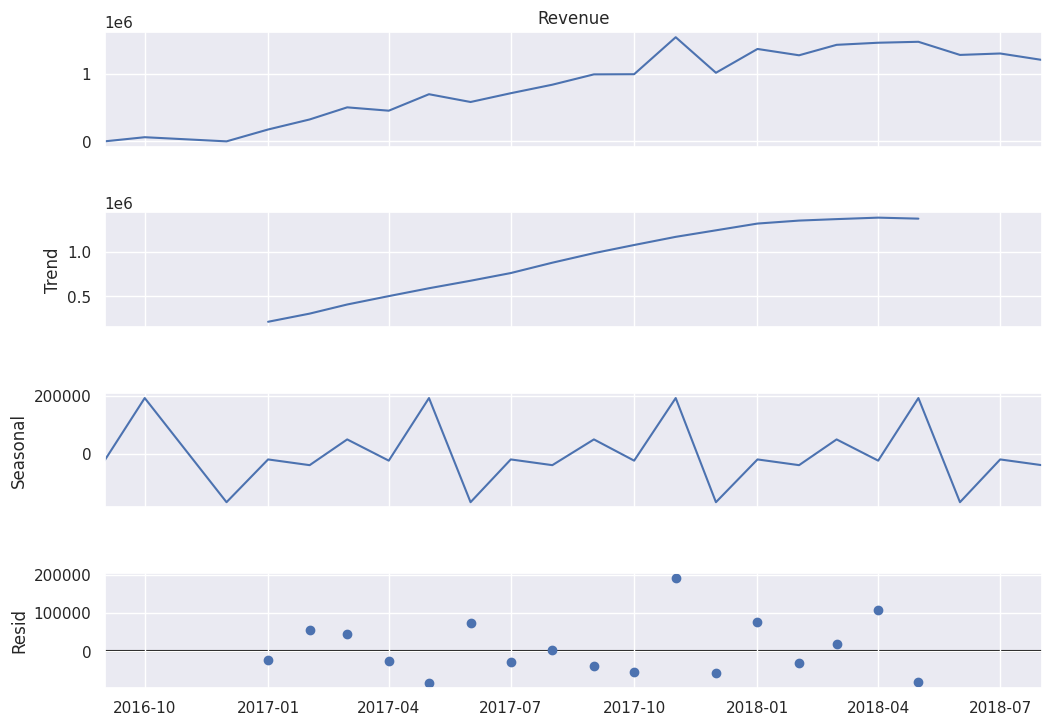

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Set time index
monthly_sales.set_index('Month', inplace=True)

# Use 6-month seasonality since dataset < 24 months
decomposition = seasonal_decompose(monthly_sales['Revenue'], model='additive', period=6)

# Plot decomposition
fig = decomposition.plot()
fig.set_size_inches(12,8)
plt.show()

# Reset index for Prophet use later
monthly_sales = monthly_sales.reset_index()


##Prophet Forecasting

In [ ]:
from prophet import Prophet

# Prepare data for Prophet
prophet_data = monthly_sales.rename(columns={'Month':'ds','Revenue':'y'})

print(prophet_data.head())


          ds          y
0 2016-09-01       0.00
1 2016-10-01   61746.94
2 2016-12-01      19.62
3 2017-01-01  176491.49
4 2017-02-01  325782.66


In [ ]:
# Initialize and fit model
model = Prophet(yearly_seasonality=True, daily_seasonality=False)
model.fit(prophet_data)

# Create future dataframe (forecast next 6 months)
future = model.make_future_dataframe(periods=6, freq='M')
forecast = model.predict(future)

# Show forecasted values
forecast[['ds','yhat','yhat_lower','yhat_upper']].tail(10)


INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:n_changepoints greater than number of observations. Using 17.
DEBUG:cmdstanpy:input tempfile: /tmp/tmptyskrnei/jaeluutg.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmptyskrnei/n1wwlqce.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=29248', 'data', 'file=/tmp/tmptyskrnei/jaeluutg.json', 'init=/tmp/tmptyskrnei/n1wwlqce.json', 'output', 'file=/tmp/tmptyskrnei/prophet_modelle94f_ra/prophet_model-20250831152113.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
15:21:13 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
15:21:13 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing
/usr/local/lib/python3.12/dist-packages/prophet/forecaster.py:18

,ds,yhat,yhat_lower,yhat_upper
19,2018-05-01,1.493149e+06,1.400949e+06,1.580826e+06
20,2018-06-01,1.346072e+06,1.256178e+06,1.434565e+06
21,2018-07-01,1.396609e+06,1.301603e+06,1.497244e+06
22,2018-08-01,1.304744e+06,1.210673e+06,1.396869e+06
23,2018-08-31,3.664864e+06,3.569076e+06,3.761809e+06
24,2018-09-30,2.777275e+06,2.680530e+06,2.869994e+06
25,2018-10-31,-2.370803e+05,-3.356012e+05,-1.429998e+05
26,2018-11-30,2.445957e+06,2.354463e+06,2.541670e+06
27,2018-12-31,3.144815e+06,3.055809e+06,3.235534e+06
28,2019-01-31,1.504691e+06,1.411067e+06,1.595914e+06


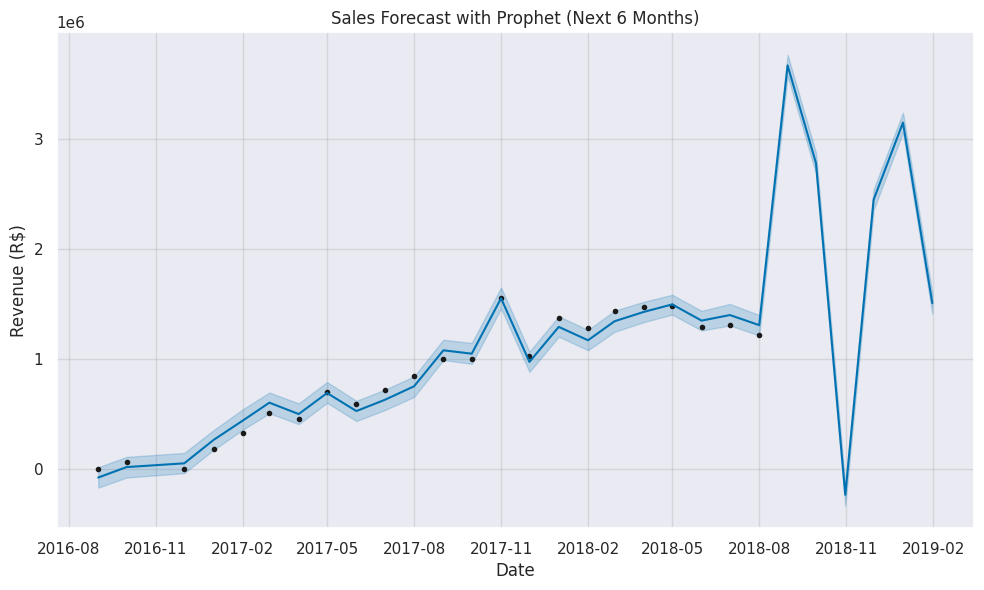

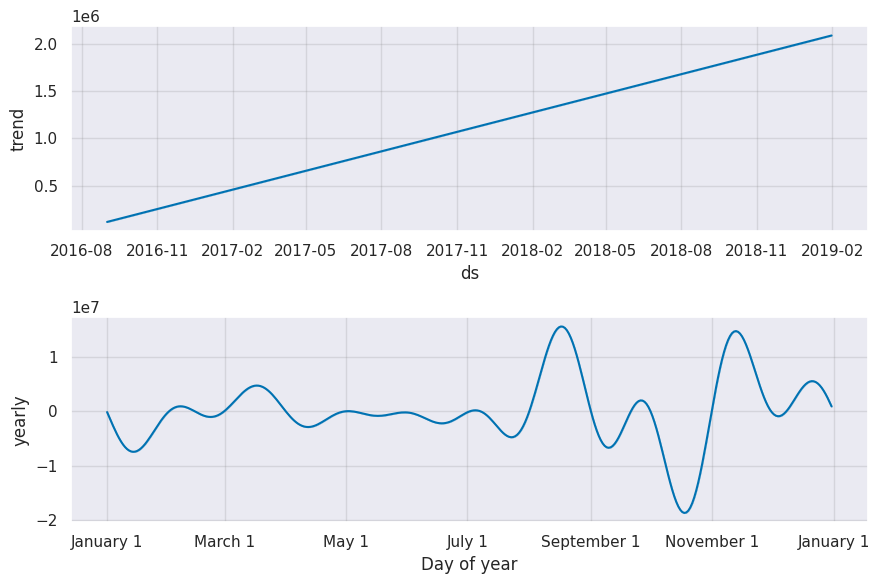

In [ ]:
# Plot forecast
fig1 = model.plot(forecast)
plt.title("Sales Forecast with Prophet (Next 6 Months)")
plt.xlabel("Date")
plt.ylabel("Revenue (R$)")
plt.show()

# Plot components (trend + seasonality)
fig2 = model.plot_components(forecast)
plt.show()


##ARIMA Forecasting

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Use the monthly_sales dataframe again
arima_data = monthly_sales.set_index('Month')['Revenue']

# Build ARIMA model (basic order, can tune later)
model_arima = ARIMA(arima_data, order=(1,1,1))   # (p,d,q)
arima_fit = model_arima.fit()

print(arima_fit.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                Revenue   No. Observations:                   23
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -297.406
Date:                Sun, 31 Aug 2025   AIC                            600.813
Time:                        15:22:47   BIC                            604.086
Sample:                             0   HQIC                           601.584
                                 - 23                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7835      0.361     -2.171      0.030      -1.491      -0.076
ma.L1          0.3700      0.455      0.814      0.416      -0.521       1.261
sigma2      3.645e+10   9.52e-12   3.83e+21      0.0

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


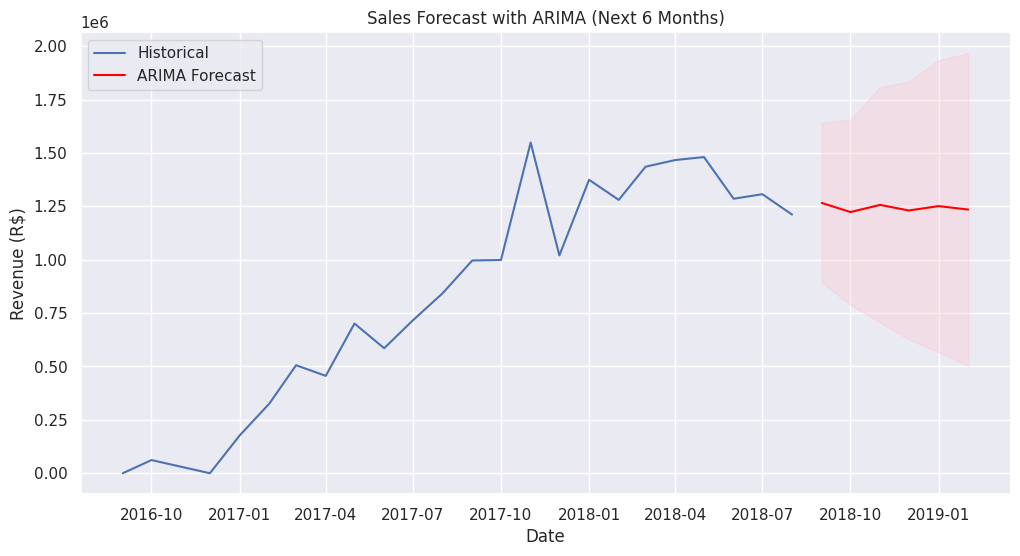

In [ ]:
import pandas as pd

# Forecast next 6 months
forecast_steps = 6
arima_forecast = arima_fit.get_forecast(steps=forecast_steps)

# Get predicted values
forecast_values = arima_forecast.predicted_mean
conf_int = arima_forecast.conf_int()

# Build proper future date index
last_date = arima_data.index[-1]  # last date in training set
future_dates = pd.date_range(start=last_date + pd.offsets.MonthBegin(1), periods=forecast_steps, freq='MS')

# Align forecast with future dates
forecast_values.index = future_dates
conf_int.index = future_dates

# Plot
plt.figure(figsize=(12,6))
plt.plot(arima_data.index, arima_data, label='Historical')
plt.plot(forecast_values.index, forecast_values, label='ARIMA Forecast', color='red')
plt.fill_between(conf_int.index, conf_int.iloc[:,0], conf_int.iloc[:,1], color='pink', alpha=0.3)
plt.title("Sales Forecast with ARIMA (Next 6 Months)")
plt.xlabel("Date")
plt.ylabel("Revenue (R$)")
plt.legend()
plt.show()


##Forecast Accuracy Comparison

In [ ]:
# Prophet retrain on train data
prophet_train = train.rename(columns={'Month':'ds','Revenue':'y'})
prophet_test = test.rename(columns={'Month':'ds','Revenue':'y'})

model_prophet = Prophet(yearly_seasonality=True, daily_seasonality=False)
model_prophet.fit(prophet_train)

# Forecast 6 months ahead
future = model_prophet.make_future_dataframe(periods=6, freq='MS')   # 'MS' = Month Start
forecast = model_prophet.predict(future)

# Merge test with forecast on ds (date)
merged = prophet_test.merge(forecast[['ds','yhat']], on='ds', how='left')

# Predictions
prophet_pred = merged['yhat'].values

# Metrics
prophet_rmse = np.sqrt(mean_squared_error(merged['y'], prophet_pred))
prophet_mape = np.mean(np.abs((merged['y'] - prophet_pred) / merged['y'])) * 100

print("Prophet RMSE:", prophet_rmse)
print("Prophet MAPE:", prophet_mape, "%")


INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:n_changepoints greater than number of observations. Using 12.
DEBUG:cmdstanpy:input tempfile: /tmp/tmptyskrnei/pnobuux5.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmptyskrnei/6cas07hd.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=16140', 'data', 'file=/tmp/tmptyskrnei/pnobuux5.json', 'init=/tmp/tmptyskrnei/6cas07hd.json', 'output', 'file=/tmp/tmptyskrnei/prophet_model300j3xp6/prophet_model-20250831161407.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
16:14:07 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
16:14:20 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


Prophet RMSE: 984536.3123725734
Prophet MAPE: 64.86133661935503 %


In [ ]:
# Train ARIMA only on training data
arima_train = train.set_index('Month')['Revenue']
arima_test = test.set_index('Month')['Revenue']

model_arima = ARIMA(arima_train, order=(1,1,1))
arima_fit = model_arima.fit()

# Forecast test period
arima_forecast = arima_fit.forecast(steps=6)

# Metrics
arima_rmse = np.sqrt(mean_squared_error(arima_test, arima_forecast))
arima_mape = np.mean(np.abs((arima_test - arima_forecast) / arima_test)) * 100

print("ARIMA RMSE:", arima_rmse)
print("ARIMA MAPE:", arima_mape, "%")


ARIMA RMSE: 96369.46085016713
ARIMA MAPE: nan %


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/p

In [ ]:
# Train-test split (same as Prophet)
train = monthly_sales.iloc[:-6]
test = monthly_sales.iloc[-6:]

# Train ARIMA on training data
arima_train = train.set_index('Month')['Revenue']
arima_test = test.set_index('Month')['Revenue']

model_arima = ARIMA(arima_train, order=(1,1,1))
arima_fit = model_arima.fit()

# Forecast for test period (6 months ahead)
arima_forecast = arima_fit.get_forecast(steps=6)
arima_pred = arima_forecast.predicted_mean
arima_conf = arima_forecast.conf_int()

# Align forecast with test dates
arima_pred.index = arima_test.index
arima_conf.index = arima_test.index

# Metrics
arima_rmse = np.sqrt(mean_squared_error(arima_test, arima_pred))
arima_mape = np.mean(np.abs((arima_test - arima_pred) / arima_test)) * 100

print("ARIMA RMSE:", arima_rmse)
print("ARIMA MAPE:", arima_mape, "%")


ARIMA RMSE: 96369.46085016713
ARIMA MAPE: 6.161956789566428 %


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/p

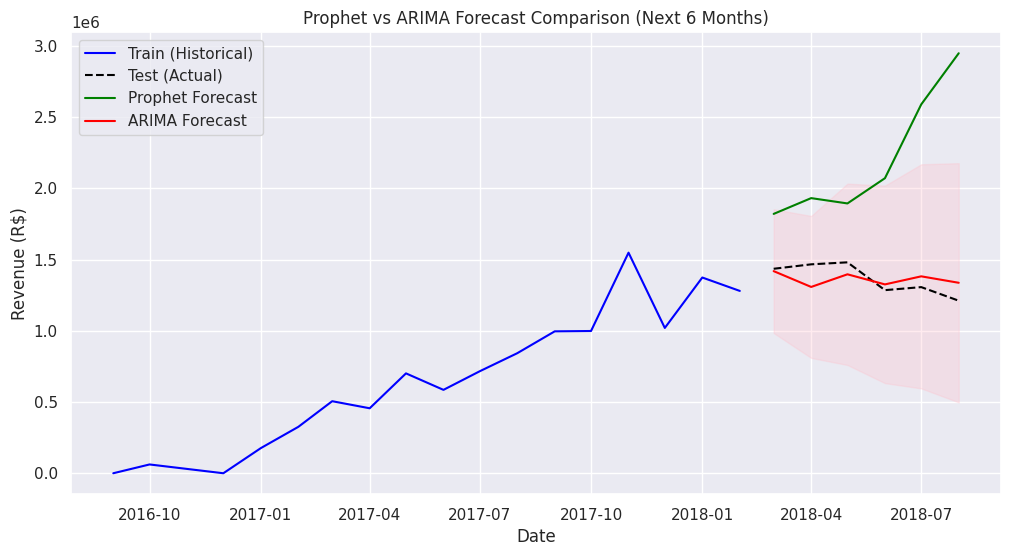

In [ ]:
# Prophet forecast values (already computed in merged DataFrame earlier)
prophet_plot = forecast.set_index('ds').loc[test['Month'], 'yhat']

plt.figure(figsize=(12,6))

# Historical data
plt.plot(train['Month'], train['Revenue'], label="Train (Historical)", color="blue")
plt.plot(test['Month'], test['Revenue'], label="Test (Actual)", color="black", linestyle="dashed")

# Prophet forecast
plt.plot(test['Month'], prophet_plot, label="Prophet Forecast", color="green")

# ARIMA forecast
plt.plot(arima_pred.index, arima_pred, label="ARIMA Forecast", color="red")

# Shaded confidence for ARIMA
plt.fill_between(arima_conf.index, arima_conf.iloc[:,0], arima_conf.iloc[:,1], color='pink', alpha=0.3)

plt.title("Prophet vs ARIMA Forecast Comparison (Next 6 Months)")
plt.xlabel("Date")
plt.ylabel("Revenue (R$)")
plt.legend()
plt.show()


##CLV Analysis

In [ ]:
# Average Order Value (AOV)
total_revenue = master_data['payment_value'].sum()
total_orders = master_data['order_id'].nunique()

aov = total_revenue / total_orders
print(f"Average Order Value (AOV): R$ {aov:,.2f}")


Average Order Value (AOV): R$ 204.98


In [ ]:
# Purchase Frequency = Total Orders / Unique Customers
unique_customers = master_data['customer_unique_id'].nunique()
purchase_frequency = total_orders / unique_customers

print(f"Purchase Frequency: {purchase_frequency:.2f} orders per customer")


Purchase Frequency: 1.03 orders per customer


In [ ]:
# Calculate customer lifespan in months
customer_span = master_data.groupby('customer_unique_id')['order_purchase_timestamp'].agg(['min','max'])
customer_span['lifespan_months'] = ((customer_span['max'] - customer_span['min']).dt.days / 30).clip(lower=1)

avg_lifespan = customer_span['lifespan_months'].mean()
print(f"Average Customer Lifespan: {avg_lifespan:.2f} months")


Average Customer Lifespan: 1.07 months


In [ ]:
# Estimate CLV
clv = aov * purchase_frequency * avg_lifespan
print(f"Estimated Average CLV per Customer: R$ {clv:,.2f}")


Estimated Average CLV per Customer: R$ 226.62


##RFM-Based CLV Segmentation

#####CLVi​=AOVi​×Frequencyi​×Lifespani​

In [ ]:
# AOV per customer = total revenue / total orders for that customer
customer_orders = master_data.groupby('customer_unique_id').agg({
    'order_id': 'nunique',
    'payment_value': 'sum',
    'order_purchase_timestamp': ['min','max']
}).reset_index()

customer_orders.columns = ['customer_unique_id','Total_Orders','Revenue','First_Purchase','Last_Purchase']

# Average Order Value per customer
customer_orders['AOV'] = customer_orders['Revenue'] / customer_orders['Total_Orders']

# Purchase Frequency = total orders
customer_orders['Frequency'] = customer_orders['Total_Orders']

# Lifespan in months (at least 1)
customer_orders['Lifespan_Months'] = ((customer_orders['Last_Purchase'] - customer_orders['First_Purchase']).dt.days / 30).clip(lower=1)

# CLV for each customer
customer_orders['CLV'] = customer_orders['AOV'] * customer_orders['Frequency'] * customer_orders['Lifespan_Months']

display(customer_orders.head(10))


,customer_unique_id,Total_Orders,Revenue,First_Purchase,Last_Purchase,AOV,Frequency,Lifespan_Months,CLV
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,141.90,1,1.0,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,27.19,1,1.0,27.19
2,0000f46a3911fa3c0805444483337064,1,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,86.22,1,1.0,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,43.62,1,1.0,43.62
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,196.89,1,1.0,196.89
5,0004bd2a26a76fe21f786e4fbd80607f,1,166.98,2018-04-05 19:33:16,2018-04-05 19:33:16,166.98,1,1.0,166.98
6,00050ab1314c0e55a6ca13cf7181fecf,1,35.38,2018-04-20 12:57:23,2018-04-20 12:57:23,35.38,1,1.0,35.38
7,00053a61a98854899e70ed204dd4bafe,1,838.36,2018-02-28 11:15:41,2018-02-28 11:15:41,838.36,1,1.0,838.36
8,0005e1862207bf6ccc02e4228effd9a0,1,150.12,2017-03-04 23:32:12,2017-03-04 23:32:12,150.12,1,1.0,150.12
9,0005ef4cd20d2893f0d9fbd94d3c0d97,1,129.76,2018-03-12 15:22:12,2018-03-12 15:22:12,129.76,1,1.0,129.76


In [ ]:
# Merge with RFM Segments
rfm_clv = customer_orders.merge(rfm[['customer_unique_id','Segment']], on='customer_unique_id', how='left')

# Average CLV per Segment
segment_clv = rfm_clv.groupby('Segment').agg(
    Avg_CLV=('CLV','mean'),
    Total_CLV=('CLV','sum'),
    Customers=('customer_unique_id','nunique')
).reset_index()

# Add % share
total_clv = segment_clv['Total_CLV'].sum()
segment_clv['CLV_Share_%'] = round(segment_clv['Total_CLV'] / total_clv * 100, 2)

display(segment_clv)


,Segment,Avg_CLV,Total_CLV,Customers,CLV_Share_%
0,Champions,835.665702,5.277229e+06,6315,23.23
1,Others,200.327551,1.743551e+07,87035,76.77


/tmp/ipython-input-2451036896.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_clv, x='Segment', y='Avg_CLV', palette="viridis")


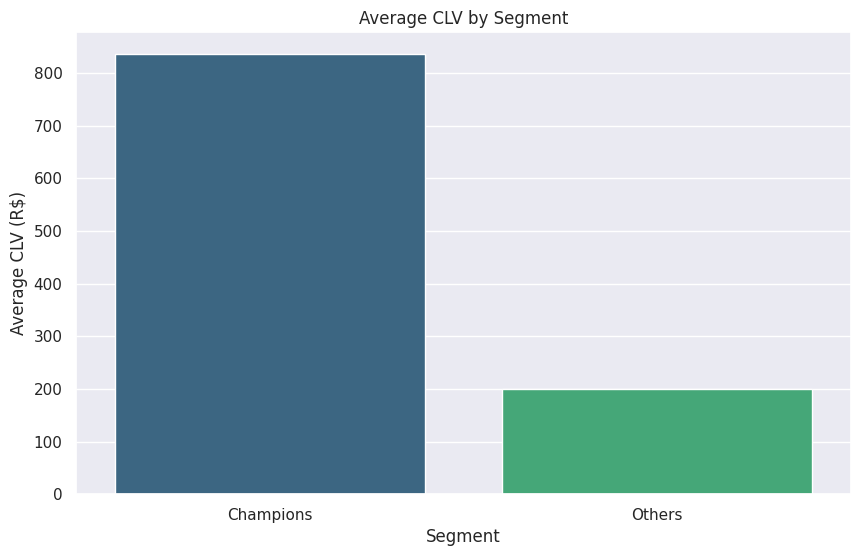

/tmp/ipython-input-2451036896.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_clv, x='Segment', y='CLV_Share_%', palette="magma")


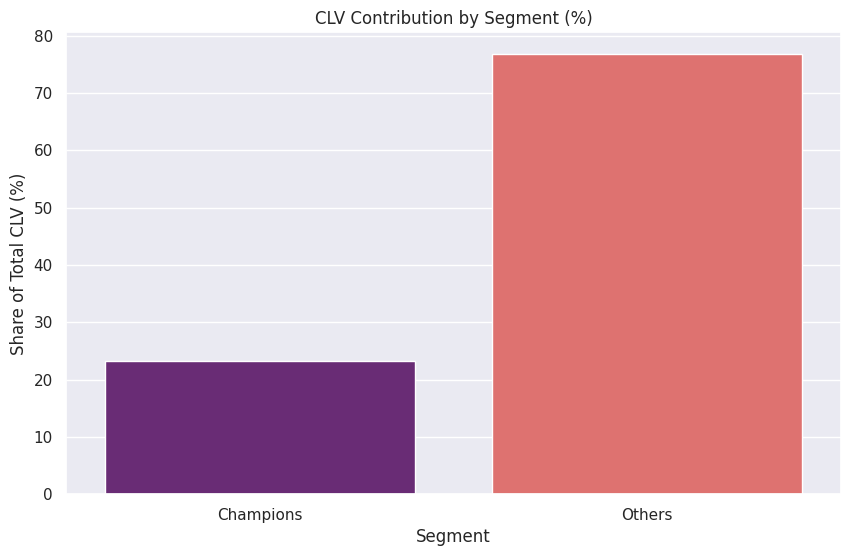

In [ ]:
# Plot CLV distribution by segment
plt.figure(figsize=(10,6))
sns.barplot(data=segment_clv, x='Segment', y='Avg_CLV', palette="viridis")
plt.title("Average CLV by Segment")
plt.ylabel("Average CLV (R$)")
plt.show()

plt.figure(figsize=(10,6))
sns.barplot(data=segment_clv, x='Segment', y='CLV_Share_%', palette="magma")
plt.title("CLV Contribution by Segment (%)")
plt.ylabel("Share of Total CLV (%)")
plt.show()


##Product Analysis

####Top 10 Products by Revenue

/tmp/ipython-input-1134318672.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products, x='payment_value', y='product_id', palette="Blues_r")


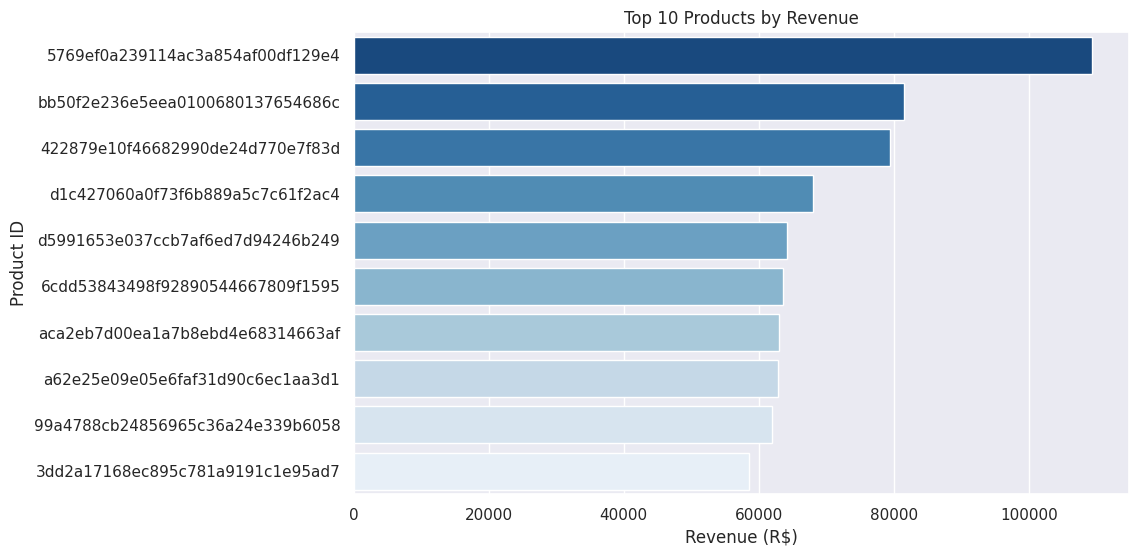

In [ ]:
# Revenue by product_id
product_sales = master_data.groupby('product_id')['payment_value'].sum().reset_index()

# Merge with product categories
product_sales = product_sales.merge(products[['product_id','product_category_name']], on='product_id', how='left')

# Top 10 products
top_products = product_sales.sort_values(by='payment_value', ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(data=top_products, x='payment_value', y='product_id', palette="Blues_r")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product ID")
plt.show()


####Top 10 Categories by Revenue

/tmp/ipython-input-778201165.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_categories, x='payment_value', y='product_category_name', palette="viridis")


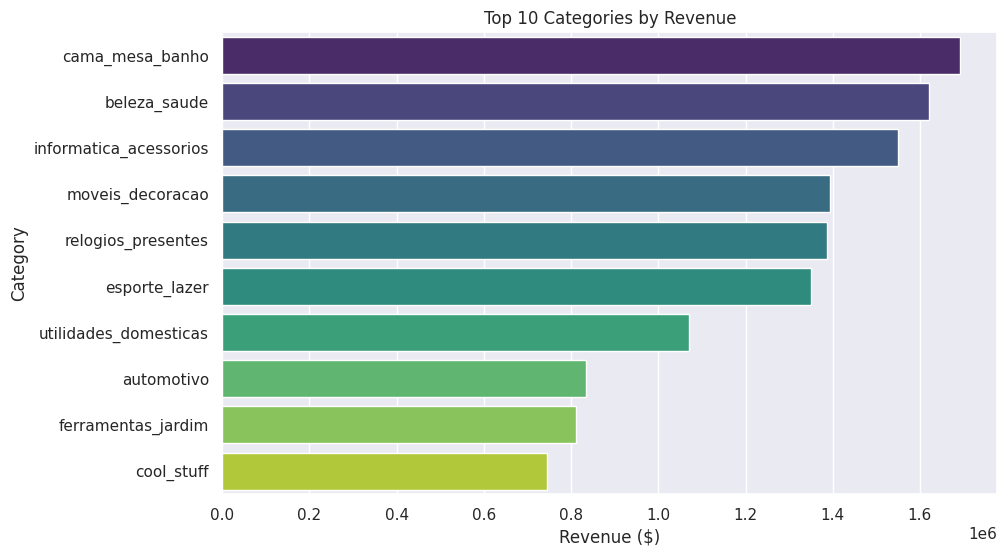

In [ ]:
# Revenue by category
category_sales = master_data.groupby('product_category_name')['payment_value'].sum().reset_index()

top_categories = category_sales.sort_values(by='payment_value', ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(data=top_categories, x='payment_value', y='product_category_name', palette="viridis")
plt.title("Top 10 Categories by Revenue")
plt.xlabel("Revenue ($)")
plt.ylabel("Category")
plt.show()


####Pareto Analysis (80/20 Rule)

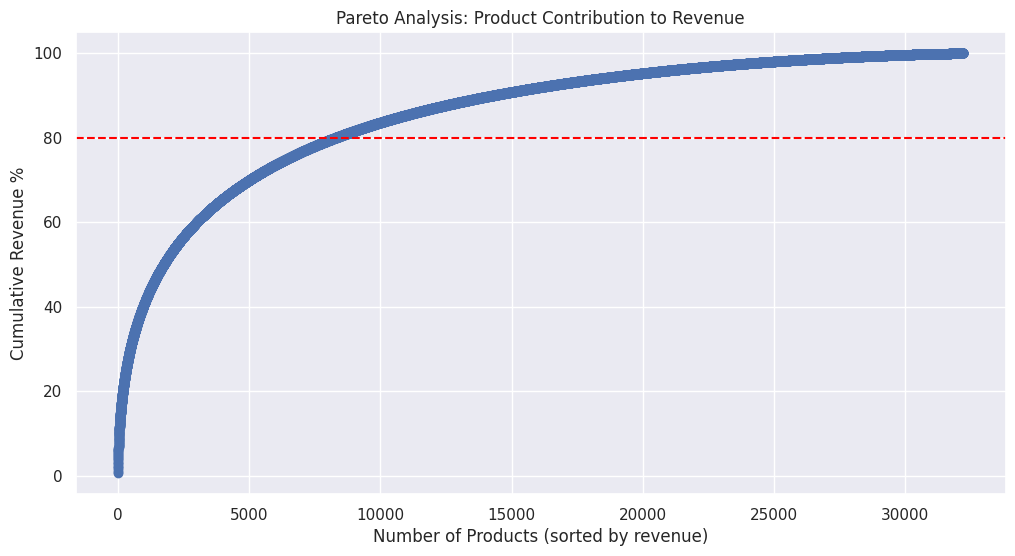

Number of products contributing to 80% revenue: 8294


In [ ]:
# Sort products by revenue
product_sales_sorted = product_sales.sort_values(by='payment_value', ascending=False)

# Cumulative revenue %
product_sales_sorted['cum_revenue'] = product_sales_sorted['payment_value'].cumsum()
product_sales_sorted['cum_revenue_pct'] = product_sales_sorted['cum_revenue'] / product_sales_sorted['payment_value'].sum() * 100

# Plot cumulative contribution
plt.figure(figsize=(12,6))
plt.plot(range(len(product_sales_sorted)), product_sales_sorted['cum_revenue_pct'], marker='o')
plt.axhline(80, color='red', linestyle='--')
plt.title("Pareto Analysis: Product Contribution to Revenue")
plt.xlabel("Number of Products (sorted by revenue)")
plt.ylabel("Cumulative Revenue %")
plt.show()

# Find number of products contributing to 80% revenue
top_80 = (product_sales_sorted['cum_revenue_pct'] <= 80).sum()
print(f"Number of products contributing to 80% revenue: {top_80}")


####High AOV Products (Niche Analysis)

/tmp/ipython-input-4064085624.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_aov_products, x='avg_order_value', y='product_id', palette="magma")


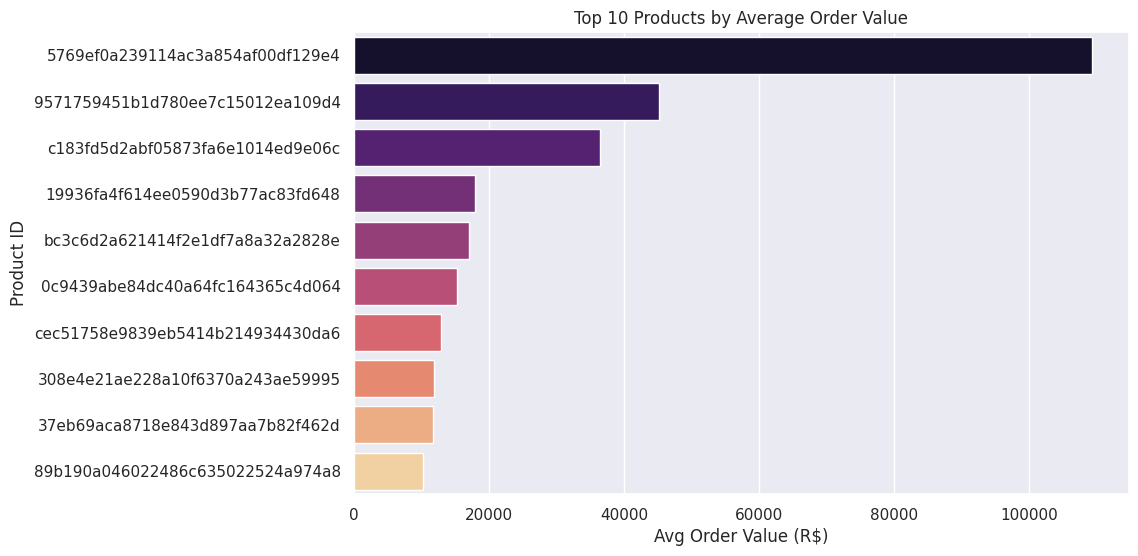

In [ ]:
# Average revenue per order item for each product
order_item_value = master_data.groupby('product_id').agg(
    total_revenue=('payment_value','sum'),
    order_count=('order_id','nunique')
).reset_index()

order_item_value['avg_order_value'] = order_item_value['total_revenue'] / order_item_value['order_count']

# Merge with categories
order_item_value = order_item_value.merge(products[['product_id','product_category_name']], on='product_id', how='left')

# Top 10 products by AOV
top_aov_products = order_item_value.sort_values(by='avg_order_value', ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(data=top_aov_products, x='avg_order_value', y='product_id', palette="magma")
plt.title("Top 10 Products by Average Order Value")
plt.xlabel("Avg Order Value (R$)")
plt.ylabel("Product ID")
plt.show()


###Cross Analysis: Bestsellers vs Niche

####Combine Revenue & AOV Rankings

In [ ]:
# Merge product revenue + AOV datasets
product_analysis = product_sales.merge(
    order_item_value[['product_id','avg_order_value']], on='product_id', how='left'
)

# Rank by revenue & AOV
product_analysis['Revenue_Rank'] = product_analysis['payment_value'].rank(ascending=False)
product_analysis['AOV_Rank'] = product_analysis['avg_order_value'].rank(ascending=False)

# Top 10 Bestsellers (Revenue)
bestsellers = product_analysis.sort_values(by='Revenue_Rank').head(10)

# Top 10 Niche / Premium Products (AOV)
premium_products = product_analysis.sort_values(by='AOV_Rank').head(10)

print("Top 10 Bestsellers (Revenue)")
display(bestsellers[['product_id','product_category_name','payment_value','avg_order_value']])

print("Top 10 Premium Products (High AOV)")
display(premium_products[['product_id','product_category_name','payment_value','avg_order_value']])


Top 10 Bestsellers (Revenue)


,product_id,product_category_name,payment_value,avg_order_value
11091,5769ef0a239114ac3a854af00df129e4,telefonia_fixa,109312.64,109312.640000
23544,bb50f2e236e5eea0100680137654686c,beleza_saude,81539.35,438.383602
8428,422879e10f46682990de24d770e7f83d,ferramentas_jardim,79512.22,225.886989
26434,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,68038.66,217.375911
26926,d5991653e037ccb7af6ed7d94246b249,informatica_acessorios,64143.26,1125.320351
13748,6cdd53843498f92890544667809f1595,beleza_saude,63665.41,430.171689
21615,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,62975.07,148.176635
20820,a62e25e09e05e6faf31d90c6ec1aa3d1,relogios_presentes,62911.77,370.069235
19289,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,61997.30,135.958991
7880,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,58625.98,231.723241


Top 10 Premium Products (High AOV)


,product_id,product_category_name,payment_value,avg_order_value
11091,5769ef0a239114ac3a854af00df129e4,telefonia_fixa,109312.64,109312.640
18747,9571759451b1d780ee7c15012ea109d4,automotivo,45256.00,45256.000
24331,c183fd5d2abf05873fa6e1014ed9e06c,agro_industria_e_comercio,36489.24,36489.240
3309,19936fa4f614ee0590d3b77ac83fd648,telefonia_fixa,35816.00,17908.000
23654,bc3c6d2a621414f2e1df7a8a32a2828e,sinalizacao_e_seguranca,17069.76,17069.760
1594,0c9439abe84dc40a64fc164365c4d064,bebidas,30479.85,15239.925
26047,cec51758e9839eb5414b214934430da6,sinalizacao_e_seguranca,12971.36,12971.360
6183,308e4e21ae228a10f6370a243ae59995,moveis_escritorio,11931.30,11931.300
7109,37eb69aca8718e843d897aa7b82f462d,ferramentas_jardim,11745.00,11745.000
17312,89b190a046022486c635022524a974a8,moveis_decoracao,20342.00,10171.000


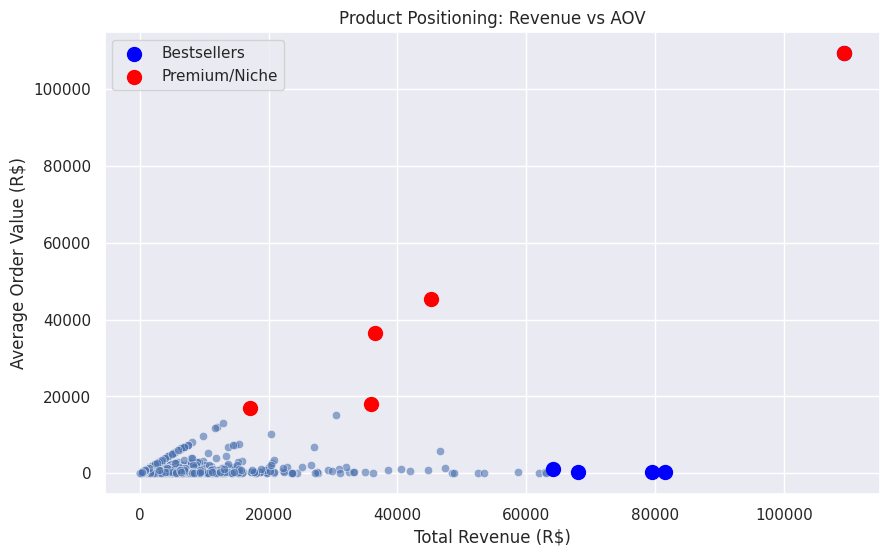

In [ ]:
# Scatter plot: Revenue vs AOV
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=product_analysis,
    x='payment_value',
    y='avg_order_value',
    alpha=0.6
)

# Highlight Top 5 Bestsellers & Premium products
top5_revenue = bestsellers.head(5)
top5_aov = premium_products.head(5)

plt.scatter(top5_revenue['payment_value'], top5_revenue['avg_order_value'], color='blue', s=100, label='Bestsellers')
plt.scatter(top5_aov['payment_value'], top5_aov['avg_order_value'], color='red', s=100, label='Premium/Niche')

plt.title("Product Positioning: Revenue vs AOV")
plt.xlabel("Total Revenue (R$)")
plt.ylabel("Average Order Value (R$)")
plt.legend()
plt.show()


##Payment Method Analysis

####Payment Type Distribution (Counts & Revenue)

,payment_type,Orders,Revenue,Order_Share_%,Revenue_Share_%
0,boleto,19784,2869361.27,19.46,17.92
1,credit_card,76505,12542084.19,75.24,78.34
2,debit_card,1528,217989.79,1.50,1.36
3,not_defined,3,0.00,0.00,0.00
4,voucher,3866,379436.87,3.80,2.37


/tmp/ipython-input-773395729.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_dist, x='Revenue', y='payment_type', palette="viridis")


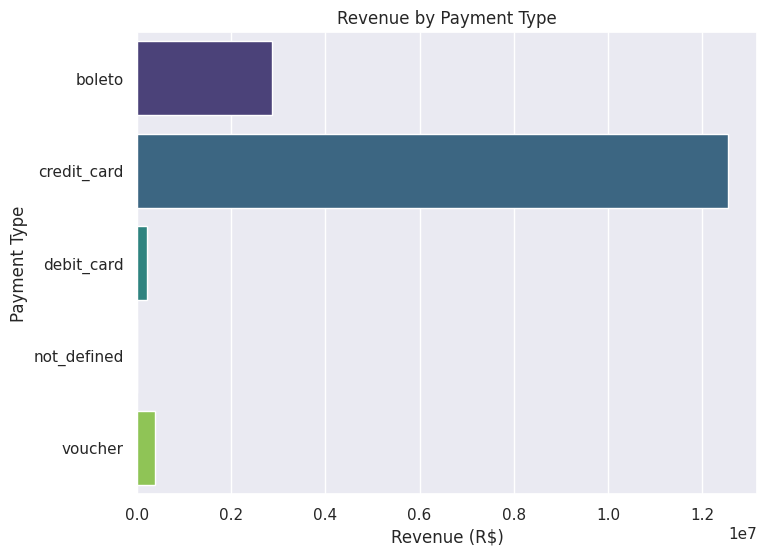

In [ ]:
# Orders by payment type
payment_dist = payments.groupby('payment_type').agg(
    Orders=('order_id','nunique'),
    Revenue=('payment_value','sum')
).reset_index()

# Add % share
total_orders = payment_dist['Orders'].sum()
total_revenue = payment_dist['Revenue'].sum()
payment_dist['Order_Share_%'] = round(payment_dist['Orders'] / total_orders * 100, 2)
payment_dist['Revenue_Share_%'] = round(payment_dist['Revenue'] / total_revenue * 100, 2)

display(payment_dist)

# Plot distribution
plt.figure(figsize=(8,6))
sns.barplot(data=payment_dist, x='Revenue', y='payment_type', palette="viridis")
plt.title("Revenue by Payment Type")
plt.xlabel("Revenue (R$)")
plt.ylabel("Payment Type")
plt.show()


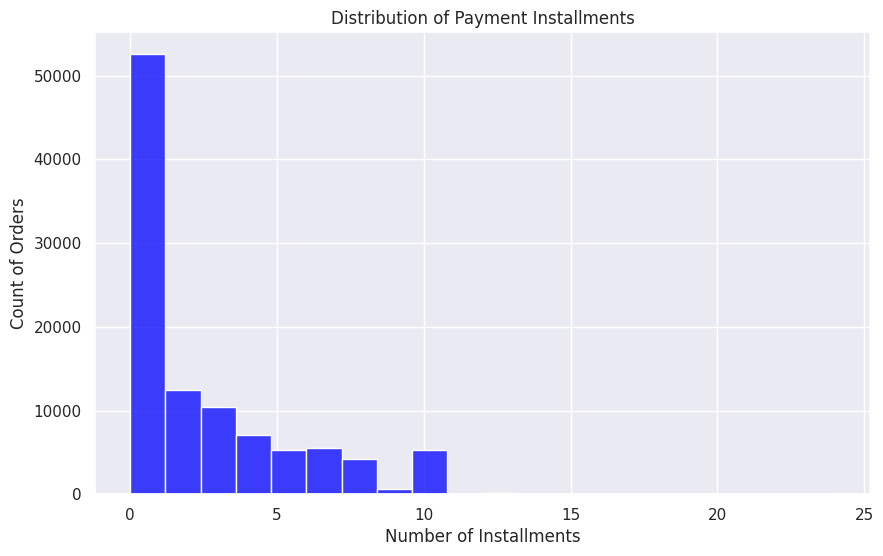

In [ ]:
# Distribution of installment counts
plt.figure(figsize=(10,6))
sns.histplot(payments['payment_installments'], bins=20, kde=False, color="blue")
plt.title("Distribution of Payment Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Count of Orders")
plt.show()


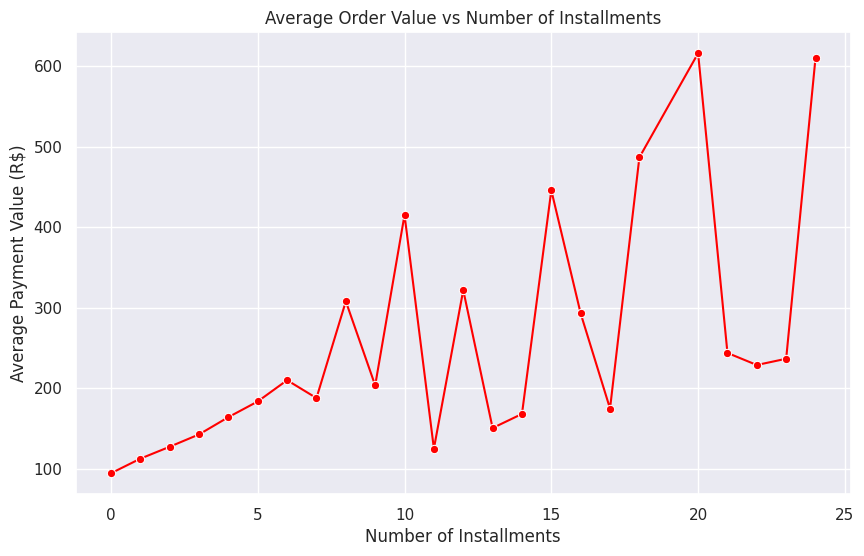

In [ ]:
# Average payment value per installment count (directly from payments table)
installment_aov = payments.groupby('payment_installments')['payment_value'].mean().reset_index()

plt.figure(figsize=(10,6))
sns.lineplot(data=installment_aov, x='payment_installments', y='payment_value', marker="o", color="red")
plt.title("Average Order Value vs Number of Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Average Payment Value (R$)")
plt.show()


##Delivery Performance Analysis

####Compute Delivery Times & Delays

In [ ]:
# Compute delivery times
delivery = master_data.copy()

# Actual delivery time (days)
delivery['actual_delivery_days'] = (delivery['order_delivered_customer_date'] - delivery['order_purchase_timestamp']).dt.days

# Estimated delivery time (days)
delivery['estimated_delivery_days'] = (delivery['order_estimated_delivery_date'] - delivery['order_purchase_timestamp']).dt.days

# Delivery delay (days) = actual - estimated
delivery['delivery_delay_days'] = (delivery['order_delivered_customer_date'] - delivery['order_estimated_delivery_date']).dt.days

# Flag late deliveries
delivery['late_delivery'] = delivery['delivery_delay_days'].apply(lambda x: "Late" if x > 0 else "On-time/Early")

display(delivery[['order_id','actual_delivery_days','estimated_delivery_days','delivery_delay_days','late_delivery']].head(10))


,order_id,actual_delivery_days,estimated_delivery_days,delivery_delay_days,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,8,15,-8,On-time/Early
1,e481f51cbdc54678b7cc49136f2d6af7,8,15,-8,On-time/Early
2,e481f51cbdc54678b7cc49136f2d6af7,8,15,-8,On-time/Early
3,53cdb2fc8bc7dce0b6741e2150273451,13,19,-6,On-time/Early
4,47770eb9100c2d0c44946d9cf07ec65d,9,26,-18,On-time/Early
5,949d5b44dbf5de918fe9c16f97b45f8a,13,26,-13,On-time/Early
6,ad21c59c0840e6cb83a9ceb5573f8159,2,12,-10,On-time/Early
7,a4591c265e18cb1dcee52889e2d8acc3,16,22,-6,On-time/Early
8,6514b8ad8028c9f2cc2374ded245783f,9,21,-12,On-time/Early
9,76c6e866289321a7c93b82b54852dc33,9,41,-32,On-time/Early


####% Late vs On-time Deliveries

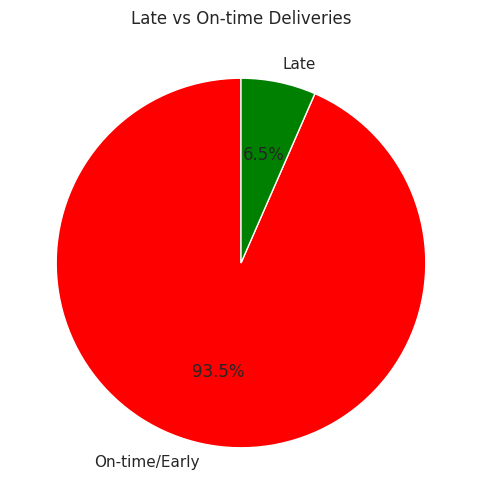

late_delivery
On-time/Early    93.454751
Late              6.545249
Name: proportion, dtype: float64


In [ ]:
# Count late vs on-time deliveries
delivery_status = delivery['late_delivery'].value_counts(normalize=True) * 100

plt.figure(figsize=(6,6))
plt.pie(delivery_status, labels=delivery_status.index, autopct='%1.1f%%', startangle=90, colors=['red','green'])
plt.title("Late vs On-time Deliveries")
plt.show()

print(delivery_status)


####Delivery Delay by Category

/tmp/ipython-input-85264902.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_delay.head(10), x='delivery_delay_days', y='product_category_name', palette="magma")


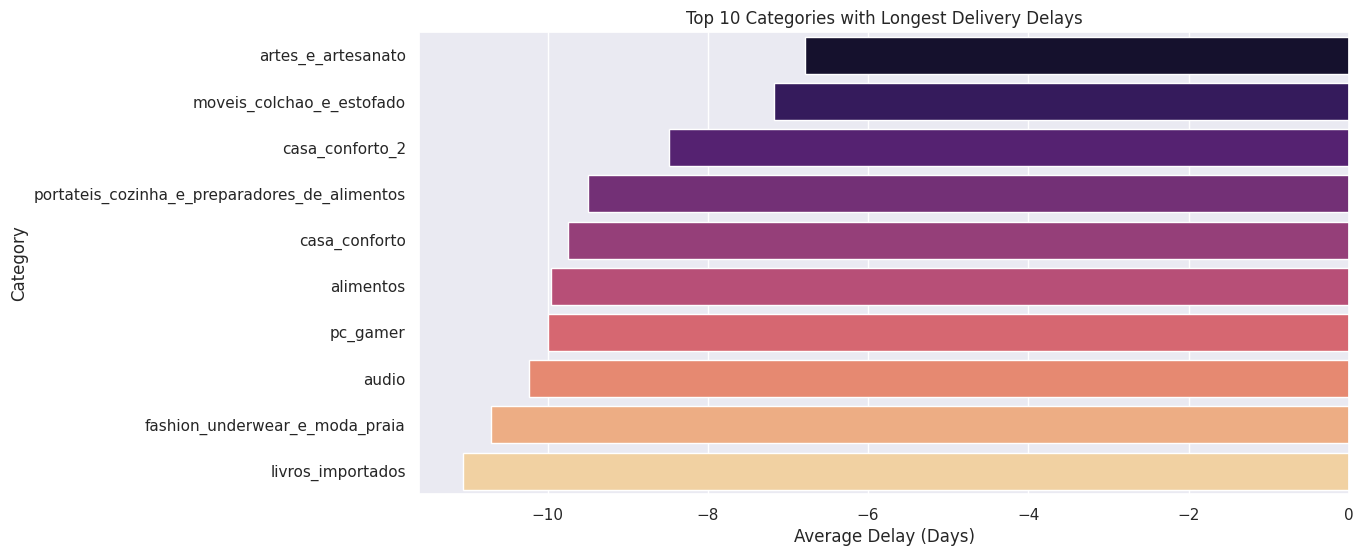

In [ ]:
# Average delivery delay by product category
category_delay = delivery.groupby('product_category_name')['delivery_delay_days'].mean().reset_index().sort_values(by='delivery_delay_days', ascending=False)

plt.figure(figsize=(12,6))
sns.barplot(data=category_delay.head(10), x='delivery_delay_days', y='product_category_name', palette="magma")
plt.title("Top 10 Categories with Longest Delivery Delays")
plt.xlabel("Average Delay (Days)")
plt.ylabel("Category")
plt.show()


####Delivery vs Customer Reviews

/tmp/ipython-input-1717456017.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=review_vs_delivery, x='late_delivery', y='review_score', palette="viridis")


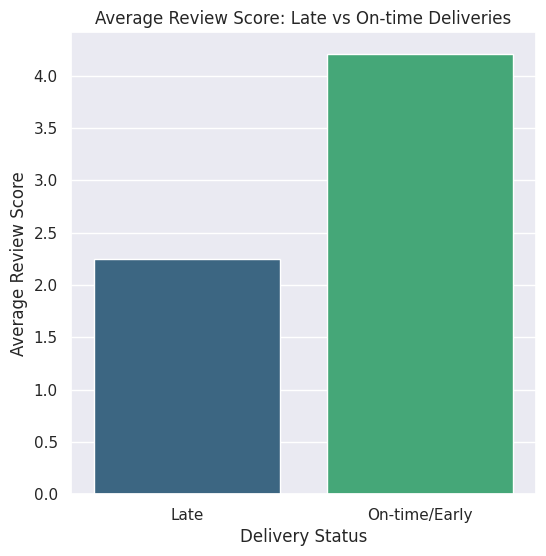

   late_delivery  review_score
0           Late      2.253292
1  On-time/Early      4.205690


In [ ]:
# Merge delivery with reviews
delivery_reviews = delivery.merge(reviews[['order_id','review_score']], on='order_id', how='left')

# Average review score by late/on-time
review_vs_delivery = delivery_reviews.groupby('late_delivery')['review_score'].mean().reset_index()

plt.figure(figsize=(6,6))
sns.barplot(data=review_vs_delivery, x='late_delivery', y='review_score', palette="viridis")
plt.title("Average Review Score: Late vs On-time Deliveries")
plt.ylabel("Average Review Score")
plt.xlabel("Delivery Status")
plt.show()

print(review_vs_delivery)


##Review Analysis

####Review Score Distribution

/tmp/ipython-input-3627357386.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=reviews, x='review_score', palette="viridis")


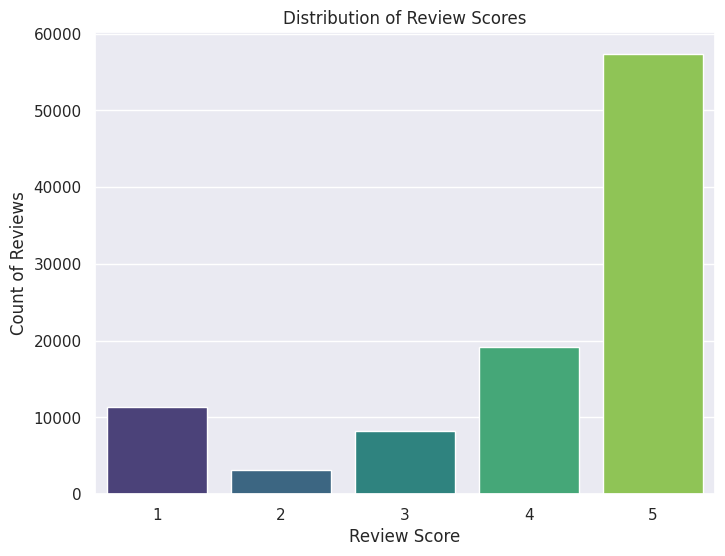

Average Review Score: 4.09/5


In [ ]:
# Distribution of review scores
plt.figure(figsize=(8,6))
sns.countplot(data=reviews, x='review_score', palette="viridis")
plt.title("Distribution of Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Count of Reviews")
plt.show()

# Average review score
avg_score = reviews['review_score'].mean()
print(f"Average Review Score: {avg_score:.2f}/5")


####Reviews vs Repeat Purchases

/tmp/ipython-input-1444729045.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=review_repeat, x='customer_type', y='review_score', palette="magma")


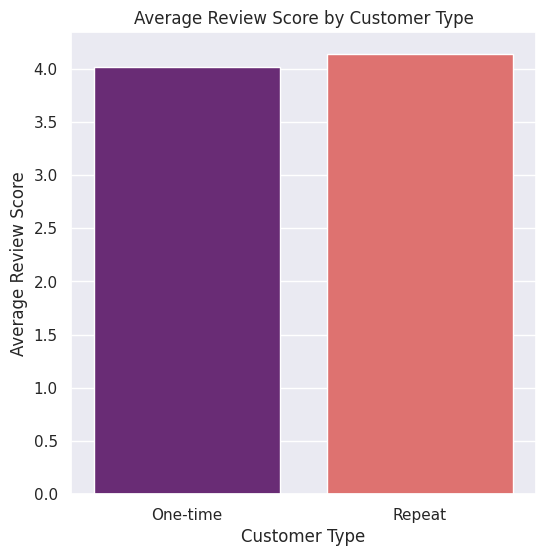

  customer_type  review_score
0      One-time      4.015585
1        Repeat      4.136146


In [ ]:
# Merge reviews with customer data
reviews_customers = reviews.merge(master_data[['order_id','customer_unique_id']], on='order_id', how='left')

# Count how many orders each customer placed
customer_order_counts = master_data.groupby('customer_unique_id')['order_id'].nunique().reset_index()
customer_order_counts.columns = ['customer_unique_id','total_orders']

# Merge with reviews
reviews_customers = reviews_customers.merge(customer_order_counts, on='customer_unique_id', how='left')

# Flag repeat customers
reviews_customers['customer_type'] = reviews_customers['total_orders'].apply(lambda x: "Repeat" if x > 1 else "One-time")

# Average review score by customer type
review_repeat = reviews_customers.groupby('customer_type')['review_score'].mean().reset_index()

plt.figure(figsize=(6,6))
sns.barplot(data=review_repeat, x='customer_type', y='review_score', palette="magma")
plt.title("Average Review Score by Customer Type")
plt.ylabel("Average Review Score")
plt.xlabel("Customer Type")
plt.show()

print(review_repeat)


####Review Comments Analysis

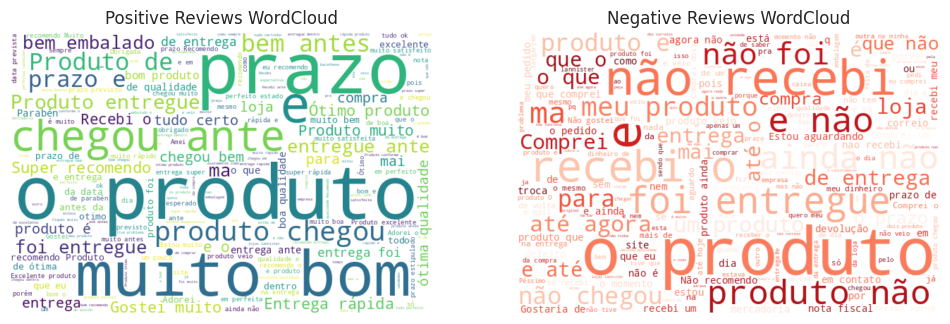

In [ ]:
# Check if review comments exist
if 'review_comment_message' in reviews.columns:
    from wordcloud import WordCloud

    # Positive reviews (score >=4)
    positive_comments = " ".join(reviews[reviews['review_score'] >= 4]['review_comment_message'].dropna())

    # Negative reviews (score <=2)
    negative_comments = " ".join(reviews[reviews['review_score'] <= 2]['review_comment_message'].dropna())

    # Word clouds
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    wc_pos = WordCloud(width=600, height=400, background_color='white').generate(positive_comments)
    plt.imshow(wc_pos, interpolation='bilinear')
    plt.axis("off")
    plt.title("Positive Reviews WordCloud")

    plt.subplot(1,2,2)
    wc_neg = WordCloud(width=600, height=400, background_color='white', colormap="Reds").generate(negative_comments)
    plt.imshow(wc_neg, interpolation='bilinear')
    plt.axis("off")
    plt.title("Negative Reviews WordCloud")

    plt.show()
